In [39]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/willianoliveiragibin/animal-condition/data.csv


In [40]:

from pathlib import Path

# Liet ke cac file du lieu
data_files = list(
    Path("/kaggle/input").rglob("*")
)

# Chi hien thi file CSV va Excel
for file in data_files:
    if file.is_file() and file.suffix.lower() in [
        ".csv", ".xlsx", ".xls"
    ]:
        print(file)


/kaggle/input/datasets/willianoliveiragibin/animal-condition/data.csv


In [41]:

import pandas as pd
from pathlib import Path

# Tim tat ca file CSV
csv_files = list(
    Path("/kaggle/input").rglob("*.csv")
)

if len(csv_files) != 1:
    raise ValueError(
        f"Tim thay {len(csv_files)} file CSV. "
        "Hay kiem tra va chon dung file Animal Condition."
    )

# Doc du lieu
df = pd.read_csv(csv_files[0])

print("Kich thuoc du lieu:", df.shape)

print("\nDanh sach cac cot:")
print(df.columns.tolist())

print("\n5 dong dau tien:")
display(df.head())


Kich thuoc du lieu: (871, 7)

Danh sach cac cot:
['AnimalName', 'symptoms1', 'symptoms2', 'symptoms3', 'symptoms4', 'symptoms5', 'Dangerous']

5 dong dau tien:


,AnimalName,symptoms1,symptoms2,symptoms3,symptoms4,symptoms5,Dangerous
0,Dog,Fever,Diarrhea,Vomiting,Weight loss,Dehydration,Yes
1,Dog,Fever,Diarrhea,Coughing,Tiredness,Pains,Yes
2,Dog,Fever,Diarrhea,Coughing,Vomiting,Anorexia,Yes
3,Dog,Fever,Difficulty breathing,Coughing,Lethargy,Sneezing,Yes
4,Dog,Fever,Diarrhea,Coughing,Lethargy,Blue Eye,Yes


In [42]:

print("THONG TIN DATASET:")
df.info()

print("\nSO GIA TRI THIEU:")
print(df.isnull().sum())

print("\nSO DONG TRUNG LAP:")
print(df.duplicated().sum())

print("\nTHONG KE DU LIEU:")
display(df.describe(include="all"))


THONG TIN DATASET:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 871 entries, 0 to 870
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   AnimalName  871 non-null    object
 1   symptoms1   871 non-null    object
 2   symptoms2   871 non-null    object
 3   symptoms3   871 non-null    object
 4   symptoms4   871 non-null    object
 5   symptoms5   871 non-null    object
 6   Dangerous   869 non-null    object
dtypes: object(7)
memory usage: 47.8+ KB

SO GIA TRI THIEU:
AnimalName    0
symptoms1     0
symptoms2     0
symptoms3     0
symptoms4     0
symptoms5     0
Dangerous     2
dtype: int64

SO DONG TRUNG LAP:
28

THONG KE DU LIEU:


,AnimalName,symptoms1,symptoms2,symptoms3,symptoms4,symptoms5,Dangerous
count,871,871,871,871,871,871,869
unique,46,232,230,229,217,203,2
top,Buffaloes,Fever,Diarrhea,Coughing,Weight loss,Pains,Yes
freq,129,257,119,95,117,99,849


In [43]:

# Chuan hoa ten cot
df.columns = df.columns.str.strip()

# Xem danh sach cac cot
print("DANH SACH CAC COT:")
print(df.columns.tolist())

print("\nKICH THUOC DATASET:")
print(df.shape)

# Tim cot nhan Dangerous
target_col = next(
    (col for col in df.columns
     if col.lower() == "dangerous"),
    None
)

if target_col is not None:
    print("\nCot nhan du doan:", target_col)
    print(df[target_col].value_counts(dropna=False))
else:
    print("\nChua tim thay cot Dangerous.")
    print("Can xac dinh cot nhan tu dataset thuc te.")


DANH SACH CAC COT:
['AnimalName', 'symptoms1', 'symptoms2', 'symptoms3', 'symptoms4', 'symptoms5', 'Dangerous']

KICH THUOC DATASET:
(871, 7)

Cot nhan du doan: Dangerous
Dangerous
Yes    849
No      20
NaN      2
Name: count, dtype: int64


In [44]:

# Kiem tra phan bo cac lop
if target_col is not None:
    print("PHAN BO NHAN:")

    print(df[target_col].value_counts(
        dropna=False
    ))

    print("\nTY LE PHAN TRAM:")

    print(
        df[target_col].value_counts(
            normalize=True,
            dropna=False
        ) * 100
    )


PHAN BO NHAN:
Dangerous
Yes    849
No      20
NaN      2
Name: count, dtype: int64

TY LE PHAN TRAM:
Dangerous
Yes    97.474168
No      2.296211
NaN     0.229621
Name: proportion, dtype: float64


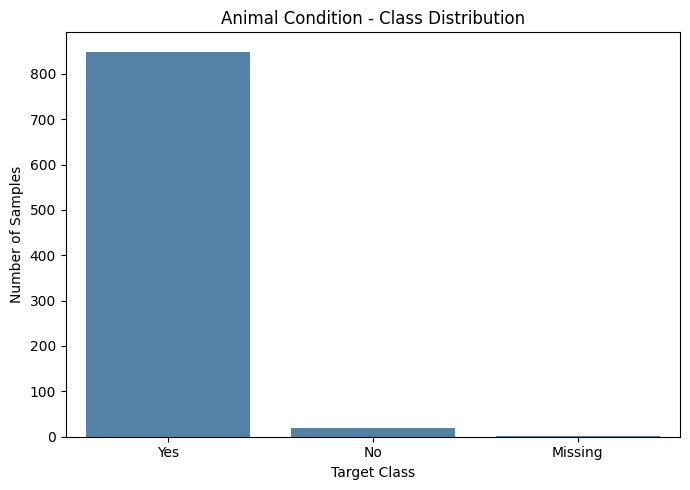

In [45]:

import matplotlib.pyplot as plt
import seaborn as sns

if target_col is not None:
    plt.figure(figsize=(7, 5))

    labels = df[target_col].fillna("Missing").astype(str)

    sns.countplot(
        x=labels,
        color="steelblue",
        order=labels.value_counts().index
    )

    plt.title("Animal Condition - Class Distribution")
    plt.xlabel("Target Class")
    plt.ylabel("Number of Samples")

    plt.tight_layout()

    plt.savefig(
        "/kaggle/working/animal_class_distribution.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


In [46]:

# Kiem tra gia tri thieu
print("GIA TRI THIEU:")
print(df.isnull().sum())

# Kiem tra du lieu trung lap
print("\nSO DONG TRUNG LAP:")
print(df.duplicated().sum())

# Kiem tra kieu du lieu
print("\nKIEU DU LIEU:")
print(df.dtypes)

# Thong ke du lieu
print("\nTHONG KE:")
display(df.describe(include="all"))


GIA TRI THIEU:
AnimalName    0
symptoms1     0
symptoms2     0
symptoms3     0
symptoms4     0
symptoms5     0
Dangerous     2
dtype: int64

SO DONG TRUNG LAP:
28

KIEU DU LIEU:
AnimalName    object
symptoms1     object
symptoms2     object
symptoms3     object
symptoms4     object
symptoms5     object
Dangerous     object
dtype: object

THONG KE:


,AnimalName,symptoms1,symptoms2,symptoms3,symptoms4,symptoms5,Dangerous
count,871,871,871,871,871,871,869
unique,46,232,230,229,217,203,2
top,Buffaloes,Fever,Diarrhea,Coughing,Weight loss,Pains,Yes
freq,129,257,119,95,117,99,849


In [47]:

# Lay cac cot dang chuoi
categorical_cols = df.select_dtypes(
    include=['object', 'category', 'string']
).columns

print("CAC COT DU LIEU PHAN LOAI:")

for col in categorical_cols:
    print("\nCot:", col)
    print("So gia tri khac nhau:", df[col].nunique())

    print("10 gia tri pho bien:")
    print(df[col].value_counts(dropna=False).head(10))


CAC COT DU LIEU PHAN LOAI:

Cot: AnimalName
So gia tri khac nhau: 46
10 gia tri pho bien:
AnimalName
Buffaloes    129
Sheep        110
Pig           63
Fowl          62
Elephant      59
Duck          56
Deer          38
Donkey        38
Birds         37
cat           36
Name: count, dtype: int64

Cot: symptoms1
So gia tri khac nhau: 232
10 gia tri pho bien:
symptoms1
Fever                      257
Fetopelvic dispropotion     21
wasting                     20
fever                       14
loss of appetite            12
Swelling                     9
Emaciation                   8
Jaundice                     8
sudden death                 8
Dyspnea                      8
Name: count, dtype: int64

Cot: symptoms2
So gia tri khac nhau: 230
10 gia tri pho bien:
symptoms2
Diarrhea                   119
Difficulty in breathing     26
Depression                  26
Loss of appetite            26
Uteria inertia              21
stumbling                   20
Loss of  appetite           19
Loss

In [48]:

import pandas as pd
import numpy as np

# Tao ban sao du lieu
df_clean = df.copy()

# Xoa khoang trang trong ten cot
df_clean.columns = df_clean.columns.str.strip()

# Xac dinh cot nhan
target_col = next(
    (col for col in df_clean.columns
     if col.lower() == "dangerous"),
    None
)

if target_col is None:
    raise ValueError(
        "Khong tim thay cot Dangerous. "
        "Hay kiem tra lai dataset."
    )

# Chuan hoa chuoi: xoa khoang trang, viet thuong
for col in df_clean.select_dtypes(
    include=['object', 'category', 'string']
).columns:
    df_clean[col] = df_clean[col].map(
        lambda x: x.strip().lower()
        if isinstance(x, str) else x
    )
    df_clean[col] = df_clean[col].replace(
        r'^\s*$', np.nan, regex=True
    )

# Loai bo dong thieu nhan
df_clean = df_clean.dropna(subset=[target_col])

# Loai bo ban ghi trung lap hoan toan
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Du lieu ban dau:", df.shape)
print("Du lieu sau xu ly:", df_clean.shape)

print("\nPhan bo nhan:")
print(df_clean[target_col].value_counts())


Du lieu ban dau: (871, 7)
Du lieu sau xu ly: (839, 7)

Phan bo nhan:
Dangerous
yes    819
no      20
Name: count, dtype: int64


In [49]:

# Tach dac trung va nhan
X = df_clean.drop(columns=[target_col])
y = df_clean[target_col]

print("Kich thuoc X:", X.shape)
print("Kich thuoc y:", y.shape)

print("\nDanh sach dac trung:")
print(X.columns.tolist())

print("\nCac lop nhan:")
print(y.value_counts())

if y.nunique() < 2:
    raise ValueError(
        "SVM can it nhat 2 lop nhan de huan luyen."
    )


Kich thuoc X: (839, 6)
Kich thuoc y: (839,)

Danh sach dac trung:
['AnimalName', 'symptoms1', 'symptoms2', 'symptoms3', 'symptoms4', 'symptoms5']

Cac lop nhan:
Dangerous
yes    819
no      20
Name: count, dtype: int64


In [50]:

from sklearn.model_selection import train_test_split

# Kiem tra so mau cua moi lop
if y.value_counts().min() < 2:
    raise ValueError(
        "Co lop nhan qua it mau de chia stratify."
    )

# Chia du lieu
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nPhan bo nhan Train:")
print(y_train.value_counts())

print("\nPhan bo nhan Test:")
print(y_test.value_counts())


X_train: (671, 6)
X_test: (168, 6)
y_train: (671,)
y_test: (168,)

Phan bo nhan Train:
Dangerous
yes    655
no      16
Name: count, dtype: int64

Phan bo nhan Test:
Dangerous
yes    164
no       4
Name: count, dtype: int64


In [51]:

# Xac dinh cot du lieu so
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

# Xac dinh cot du lieu phan loai
categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

print("CAC COT SO:")
print(numeric_features)

print("\nCAC COT PHAN LOAI:")
print(categorical_features)


CAC COT SO:
[]

CAC COT PHAN LOAI:
['AnimalName', 'symptoms1', 'symptoms2', 'symptoms3', 'symptoms4', 'symptoms5']


In [52]:

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Xu ly du lieu so
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Xu ly du lieu phan loai
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore'
    ))
])

# Ket hop cac buoc tien xu ly
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Da khoi tao bo tien xu ly thanh cong!")


Da khoi tao bo tien xu ly thanh cong!


In [53]:

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.base import clone
import time

# Xay dung Pipeline
svm_model = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('svm', SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale'
    ))
])

print("Da khoi tao mo hinh SVM thanh cong!")


Da khoi tao mo hinh SVM thanh cong!


In [54]:

# Bat dau dem thoi gian
start_time = time.time()

# Huan luyen mo hinh
svm_model.fit(X_train, y_train)

# Tinh thoi gian huan luyen
training_time = time.time() - start_time

print("Huan luyen SVM thanh cong!")
print(f"Thoi gian huan luyen: {training_time:.2f} giay")

# Hien thi cac lop da hoc
print("Cac lop phan loai:")
print(svm_model.named_steps['svm'].classes_)


Huan luyen SVM thanh cong!
Thoi gian huan luyen: 0.03 giay
Cac lop phan loai:
['no' 'yes']


In [55]:

# Du doan nhan cho tap Test
y_pred = svm_model.predict(X_test)

print("10 nhan thuc te:")
print(y_test.iloc[:10].to_numpy())

print("\n10 nhan du doan:")
print(y_pred[:10])

print("\nTong so mau Test:", len(y_test))


10 nhan thuc te:
['yes' 'yes' 'yes' 'yes' 'yes' 'yes' 'yes' 'yes' 'yes' 'yes']

10 nhan du doan:
['yes' 'yes' 'yes' 'yes' 'yes' 'yes' 'yes' 'yes' 'yes' 'yes']

Tong so mau Test: 168


In [56]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Tinh cac chi so danh gia
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    average='macro',
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    average='macro',
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    average='macro',
    zero_division=0
)

print("===== ANIMAL SVM EVALUATION =====")
print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1-score : {f1 * 100:.2f}%")

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))


===== ANIMAL SVM EVALUATION =====
Accuracy : 97.62%
Precision: 48.81%
Recall   : 50.00%
F1-score : 49.40%

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

          no       0.00      0.00      0.00         4
         yes       0.98      1.00      0.99       164

    accuracy                           0.98       168
   macro avg       0.49      0.50      0.49       168
weighted avg       0.95      0.98      0.96       168



In [57]:

import pandas as pd

# Tao bang so sanh ket qua
comparison_df = pd.DataFrame({
    'Actual': y_test.to_numpy(),
    'Predicted': y_pred
})

# Kiem tra du doan dung hay sai
comparison_df['Correct'] = (
    comparison_df['Actual'] == comparison_df['Predicted']
)

print("20 KET QUA DU DOAN DAU TIEN:")
display(comparison_df.head(20))

# Dem so luong du doan dung, sai
correct = comparison_df['Correct'].sum()
incorrect = len(comparison_df) - correct

print("\nTong so mau Test:", len(comparison_df))
print("So mau du doan dung:", correct)
print("So mau du doan sai:", incorrect)


20 KET QUA DU DOAN DAU TIEN:


,Actual,Predicted,Correct
0,yes,yes,True
1,yes,yes,True
2,yes,yes,True
3,yes,yes,True
4,yes,yes,True
5,yes,yes,True
6,yes,yes,True
7,yes,yes,True
8,yes,yes,True
9,yes,yes,True



Tong so mau Test: 168
So mau du doan dung: 164
So mau du doan sai: 4


In [58]:

from sklearn.metrics import confusion_matrix
import pandas as pd

# Lay danh sach cac lop cua mo hinh
class_labels = svm_model.named_steps['svm'].classes_

# Tao ma tran nham lan
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=class_labels
)

# Chuyen thanh DataFrame
conf_matrix = pd.DataFrame(
    cm,
    index=class_labels,
    columns=class_labels
)

print("CONFUSION MATRIX:")
display(conf_matrix)


CONFUSION MATRIX:


,no,yes
no,0,4
yes,0,164


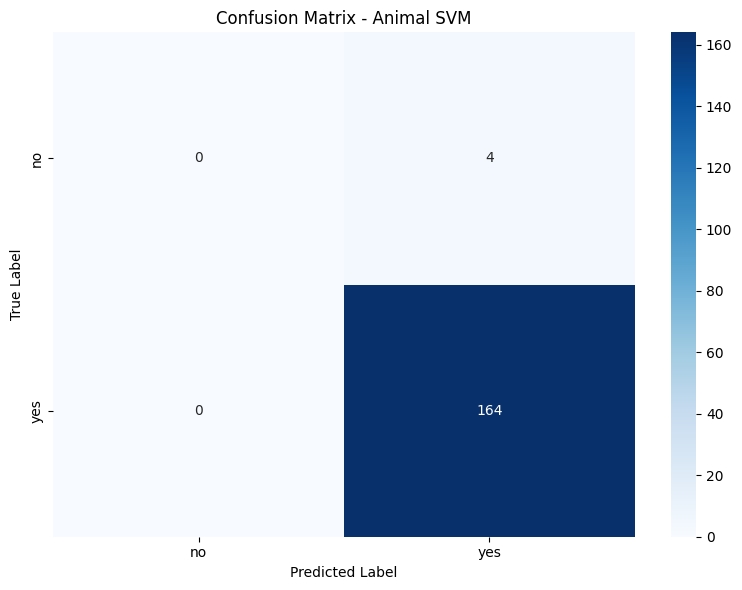

Da luu Confusion Matrix thanh cong!


In [59]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix - Animal SVM")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()

# Luu bieu do
plt.savefig(
    "/kaggle/working/animal_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Da luu Confusion Matrix thanh cong!")


In [60]:

import numpy as np
from sklearn.metrics import accuracy_score

# Tinh so luong du doan dung va sai
correct = np.trace(cm)
incorrect = cm.sum() - correct

accuracy = accuracy_score(y_test, y_pred)

print("===== ANIMAL SVM ANALYSIS =====")
print("Tong so mau Test:", len(y_test))
print("So mau du doan dung:", correct)
print("So mau du doan sai:", incorrect)
print(f"Accuracy: {accuracy * 100:.2f}%")

# So mau sai theo tung lop thuc te
print("\nSO MAU SAI THEO TUNG LOP:")

for i, label in enumerate(class_labels):
    total = cm[i].sum()
    wrong = total - cm[i, i]

    print(f"Lop {label}: {wrong}/{total} mau sai")


===== ANIMAL SVM ANALYSIS =====
Tong so mau Test: 168
So mau du doan dung: 164
So mau du doan sai: 4
Accuracy: 97.62%

SO MAU SAI THEO TUNG LOP:
Lop no: 4/4 mau sai
Lop yes: 0/164 mau sai


In [61]:

from sklearn.metrics import classification_report

# Tao bao cao dang dictionary
report_dict = classification_report(
    y_test,
    y_pred,
    labels=class_labels,
    output_dict=True,
    zero_division=0
)

# Chuyen thanh DataFrame
df_report = pd.DataFrame(report_dict).transpose()

print("CLASSIFICATION REPORT:")
display(df_report.round(4))


CLASSIFICATION REPORT:


,precision,recall,f1-score,support
no,0.0000,0.0000,0.0000,4.0000
yes,0.9762,1.0000,0.9880,164.0000
accuracy,0.9762,0.9762,0.9762,0.9762
macro avg,0.4881,0.5000,0.4940,168.0000
weighted avg,0.9529,0.9762,0.9644,168.0000


In [62]:

from pathlib import Path

output_dir = Path("/kaggle/working")
output_dir.mkdir(parents=True, exist_ok=True)

# Luu bang Classification Report
df_report.to_csv(
    output_dir / "animal_classification_report.csv",
    encoding="utf-8-sig"
)

# Tao bao cao dang van ban
report_text = classification_report(
    y_test,
    y_pred,
    labels=class_labels,
    zero_division=0
)

with open(
    output_dir / "animal_evaluation.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write("ANIMAL CONDITION SVM EVALUATION\n\n")
    f.write("Model: SVC(kernel='rbf', C=1.0, gamma='scale')\n")
    f.write(f"Training samples: {len(y_train)}\n")
    f.write(f"Testing samples: {len(y_test)}\n")
    f.write(f"Accuracy: {accuracy * 100:.2f}%\n\n")
    f.write("Confusion Matrix:\n")
    f.write(conf_matrix.to_string())
    f.write("\n\nClassification Report:\n")
    f.write(report_text)

print("Da luu bao cao Animal SVM thanh cong!")


Da luu bao cao Animal SVM thanh cong!


In [63]:

from sklearn.model_selection import train_test_split

# Lay toi da 3000 mau de toi uu
if len(X_train) > 3000:
    X_train_tune, _, y_train_tune, _ = train_test_split(
        X_train,
        y_train,
        train_size=3000,
        random_state=42,
        stratify=y_train
    )
else:
    X_train_tune = X_train.copy()
    y_train_tune = y_train.copy()

print("Train ban dau:", X_train.shape)
print("Train toi uu:", X_train_tune.shape)

print("\nPhan bo nhan:")
print(y_train_tune.value_counts())


Train ban dau: (671, 6)
Train toi uu: (671, 6)

Phan bo nhan:
Dangerous
yes    655
no      16
Name: count, dtype: int64


In [64]:

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.base import clone

# Tao Pipeline moi
pipeline = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('svm', SVC())
])

# Danh sach tham so
param_grid = [
    {
        'svm__kernel': ['linear'],
        'svm__C': [0.1, 1, 10]
    },
    {
        'svm__kernel': ['rbf'],
        'svm__C': [0.1, 1, 10],
        'svm__gamma': ['scale']
    },
    {
        'svm__kernel': ['poly'],
        'svm__C': [0.1, 1, 10],
        'svm__degree': [2, 3],
        'svm__gamma': ['scale']
    }
]

# Xac dinh so fold phu hop
min_class_count = y_train_tune.value_counts().min()

if min_class_count < 2:
    raise ValueError(
        "Co lop qua it mau de Cross-Validation."
    )

n_splits = min(3, min_class_count)

cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42
)

# Tim tham so tot nhat
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv,
    n_jobs=2,
    refit=True,
    verbose=1
)

grid_search.fit(X_train_tune, y_train_tune)

print("\nBEST PARAMETERS:")
print(grid_search.best_params_)

print(
    f"Best CV F1-macro: "
    f"{grid_search.best_score_ * 100:.2f}%"
)


Fitting 3 folds for each of 12 candidates, totalling 36 fits

BEST PARAMETERS:
{'svm__C': 10, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Best CV F1-macro: 82.83%


In [65]:

import pandas as pd

# Lay ket qua GridSearchCV
cv_results = pd.DataFrame(grid_search.cv_results_)

result_table = cv_results[[
    'params',
    'mean_test_score',
    'std_test_score',
    'rank_test_score'
]]

# Sap xep ket qua
result_table = result_table.sort_values(
    by='rank_test_score'
)

print("BANG KET QUA GRIDSEARCHCV:")
display(result_table)


BANG KET QUA GRIDSEARCHCV:


,params,mean_test_score,std_test_score,rank_test_score
5,"{'svm__C': 10, 'svm__gamma': 'scale', 'svm__ke...",0.828315,0.036925,1
11,"{'svm__C': 10, 'svm__degree': 3, 'svm__gamma':...",0.828315,0.036925,1
10,"{'svm__C': 10, 'svm__degree': 2, 'svm__gamma':...",0.828315,0.036925,1
1,"{'svm__C': 1, 'svm__kernel': 'linear'}",0.807345,0.046645,4
2,"{'svm__C': 10, 'svm__kernel': 'linear'}",0.807345,0.046645,4
4,"{'svm__C': 1, 'svm__gamma': 'scale', 'svm__ker...",0.493967,0.000533,6
3,"{'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__k...",0.493967,0.000533,6
0,"{'svm__C': 0.1, 'svm__kernel': 'linear'}",0.493967,0.000533,6
7,"{'svm__C': 0.1, 'svm__degree': 3, 'svm__gamma'...",0.493967,0.000533,6
6,"{'svm__C': 0.1, 'svm__degree': 2, 'svm__gamma'...",0.493967,0.000533,6


In [66]:

from sklearn.base import clone

# Lay cau hinh mo hinh tot nhat
best_model = clone(grid_search.best_estimator_)

# Huan luyen tren toan bo tap Train
best_model.fit(X_train, y_train)

# Du doan tren tap Test
y_pred_best = best_model.predict(X_test)

print("Huan luyen mo hinh toi uu thanh cong!")
print("Best Parameters:", grid_search.best_params_)


Huan luyen mo hinh toi uu thanh cong!
Best Parameters: {'svm__C': 10, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}


In [67]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Ham danh gia mo hinh
def evaluate_model(y_true, y_predict):
    return {
        'Accuracy': accuracy_score(
            y_true, y_predict
        ),
        'Precision': precision_score(
            y_true, y_predict,
            average='macro',
            zero_division=0
        ),
        'Recall': recall_score(
            y_true, y_predict,
            average='macro',
            zero_division=0
        ),
        'F1-score': f1_score(
            y_true, y_predict,
            average='macro',
            zero_division=0
        )
    }

# Tao bang so sanh
comparison = pd.DataFrame({
    'SVM ban dau': evaluate_model(y_test, y_pred),
    'SVM toi uu': evaluate_model(y_test, y_pred_best)
}).T

comparison_percent = (comparison * 100).round(2)

print("SO SANH MO HINH SVM:")
display(comparison_percent)


SO SANH MO HINH SVM:


,Accuracy,Precision,Recall,F1-score
SVM ban dau,97.62,48.81,50.0,49.4
SVM toi uu,100.00,100.00,100.0,100.0


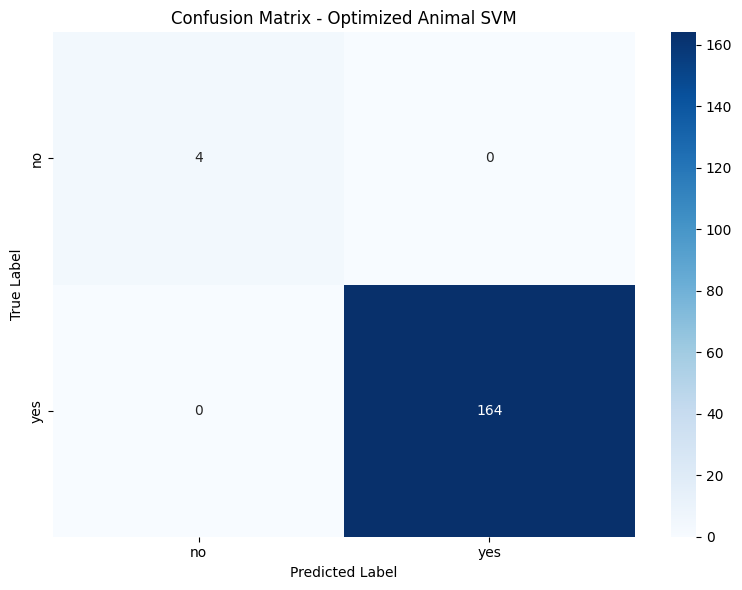

In [68]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Lay nhan cac lop
class_labels = best_model.named_steps['svm'].classes_

# Tao ma tran nham lan
cm_best = confusion_matrix(
    y_test,
    y_pred_best,
    labels=class_labels
)

# Ve Confusion Matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_best,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Confusion Matrix - Optimized Animal SVM")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/animal_optimized_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [69]:

from pathlib import Path

output_dir = Path("/kaggle/working")
output_dir.mkdir(parents=True, exist_ok=True)

# Luu ket qua GridSearchCV
result_table.to_csv(
    output_dir / "animal_gridsearch_results.csv",
    index=False
)

# Luu bang so sanh
comparison_percent.to_csv(
    output_dir / "animal_model_comparison.csv",
    encoding="utf-8-sig"
)

print("Da luu cac bang ket qua thanh cong!")


Da luu cac bang ket qua thanh cong!


In [70]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from pathlib import Path

# Thu muc luu ket qua
output_dir = Path("/kaggle/working")
output_dir.mkdir(parents=True, exist_ok=True)

# Lay cac nhan
class_labels = best_model.named_steps['svm'].classes_

# Danh gia mo hinh toi uu
final_accuracy = accuracy_score(y_test, y_pred_best)

final_report = classification_report(
    y_test,
    y_pred_best,
    labels=class_labels,
    digits=4,
    zero_division=0
)

final_cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=class_labels
)

# Luu bao cao
with open(
    output_dir / "animal_final_report.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write("ANIMAL CONDITION SVM FINAL REPORT\n\n")
    f.write(f"Dataset samples: {len(df_clean)}\n")
    f.write(f"Train samples: {len(y_train)}\n")
    f.write(f"Test samples: {len(y_test)}\n\n")

    f.write("Best Parameters:\n")
    f.write(str(grid_search.best_params_))

    f.write("\n\nBest CV F1-macro:\n")
    f.write(f"{grid_search.best_score_:.4f}")

    f.write("\n\nTest Accuracy:\n")
    f.write(f"{final_accuracy * 100:.2f}%")

    f.write("\n\nClassification Report:\n")
    f.write(final_report)

    f.write("\nConfusion Matrix:\n")
    f.write(str(final_cm))

print("Da luu animal_final_report.txt")
print(final_report)


Da luu animal_final_report.txt
              precision    recall  f1-score   support

          no     1.0000    1.0000    1.0000         4
         yes     1.0000    1.0000    1.0000       164

    accuracy                         1.0000       168
   macro avg     1.0000    1.0000    1.0000       168
weighted avg     1.0000    1.0000    1.0000       168



In [71]:

print("===== ANIMAL SVM FINAL RESULTS =====")

print("\nBest Parameters:")
print(grid_search.best_params_)

print(
    f"\nBest CV F1-macro: "
    f"{grid_search.best_score_ * 100:.2f}%"
)

print("\nSO SANH MO HINH:")
display(comparison_percent)

print("\nCONFUSION MATRIX TOI UU:")
print(final_cm)

print("\nACCURACY CUOI CUNG:")
print(f"{final_accuracy * 100:.2f}%")


===== ANIMAL SVM FINAL RESULTS =====

Best Parameters:
{'svm__C': 10, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}

Best CV F1-macro: 82.83%

SO SANH MO HINH:


,Accuracy,Precision,Recall,F1-score
SVM ban dau,97.62,48.81,50.0,49.4
SVM toi uu,100.00,100.00,100.0,100.0



CONFUSION MATRIX TOI UU:
[[  4   0]
 [  0 164]]

ACCURACY CUOI CUNG:
100.00%


### NHẬN XÉT KẾT QUẢ THỰC NGHIỆM SVM TRÊN ANIMAL CONDITION DATASET

**1. Mô tả bài toán**

Bài thực hành xây dựng mô hình Support Vector Machine (SVM) nhằm phân loại tình trạng nguy hiểm của động vật dựa trên các đặc trưng trong Animal Condition Dataset.

Dữ liệu gồm 871 mẫu và 7 cột. Trong đó, 6 đặc trưng đầu vào gồm `AnimalName`, `symptoms1`, `symptoms2`, `symptoms3`, `symptoms4`, `symptoms5`. Biến mục tiêu là `Dangerous`, gồm hai nhãn `yes` và `no`.

**2. Tiền xử lý dữ liệu**

Quá trình khám phá dữ liệu phát hiện 2 giá trị thiếu ở biến mục tiêu và 28 bản ghi trùng lặp trong dữ liệu gốc.

Sau khi chuẩn hóa chuỗi, loại bỏ các bản ghi thiếu nhãn và trùng lặp, tập dữ liệu còn 839 mẫu:

- Nhãn yes: 819 mẫu.
- Nhãn no: 20 mẫu.

Dữ liệu mất cân bằng nghiêm trọng, khi lớp yes chiếm khoảng 97,62%.

Dữ liệu được chia thành 671 mẫu huấn luyện và 168 mẫu kiểm tra theo tỷ lệ 80:20 với `random_state=42` và `stratify=y`.

Các đặc trưng đều là dữ liệu phân loại dạng chuỗi và được mã hóa bằng OneHotEncoder.

Bộ tiền xử lý được kết hợp với mô hình SVM bằng Pipeline, giúp bảo đảm việc mã hóa dữ liệu được thực hiện trong quá trình huấn luyện.

**3. Xây dựng và tối ưu mô hình**

Mô hình ban đầu sử dụng SVC với kernel RBF, C = 1 và gamma = scale.

GridSearchCV được sử dụng để khảo sát các kernel linear, RBF và polynomial, với các giá trị C gồm 0.1, 1 và 10.

Phương pháp 3-fold Stratified Cross-Validation và chỉ số F1-macro được sử dụng để lựa chọn mô hình.

Kết quả GridSearchCV lựa chọn:

- Kernel: **RBF**.
- C: **10**.
- Gamma: **scale**.
- Best CV F1-macro: **82,83%**.

Các cấu hình polynomial với C = 10 và degree = 2 hoặc 3 cũng đạt cùng điểm CV F1-macro. Cấu hình RBF được lựa chọn theo thứ tự tìm kiếm của GridSearchCV khi có nhiều kết quả đồng hạng.

**4. Kết quả đánh giá**

| Chỉ số | SVM ban đầu | SVM tối ưu |
|---|---|---|
| Accuracy | 97,62% | 100% |
| Macro Precision | 48,81% | 100% |
| Macro Recall | 50,00% | 100% |
| Macro F1-score | 49,40% | 100% |

Confusion Matrix của mô hình ban đầu:

- Lớp no: 0 dự đoán đúng, 4 dự đoán sai.
- Lớp yes: 164 dự đoán đúng, 0 dự đoán sai.

Confusion Matrix của mô hình tối ưu:

- Lớp no: 4 dự đoán đúng, 0 dự đoán sai.
- Lớp yes: 164 dự đoán đúng, 0 dự đoán sai.

**5. Phân tích kết quả**

Mô hình SVM ban đầu đạt Accuracy 97,62%, nhưng không nhận diện đúng bất kỳ mẫu nào thuộc lớp no. Nguyên nhân đáng chú ý là sự mất cân bằng lớn giữa hai lớp dữ liệu.

Sau khi tối ưu tham số bằng GridSearchCV, mô hình đạt Accuracy và Macro F1-score 100% trên tập kiểm tra.

Mô hình tối ưu đã nhận diện đúng toàn bộ 168 mẫu Test, gồm 164 mẫu yes và 4 mẫu no.

Tuy nhiên, kết quả này cần được diễn giải thận trọng. Tập kiểm tra chỉ chứa 4 mẫu thuộc lớp no, trong khi toàn bộ dữ liệu sau tiền xử lý chỉ có 20 mẫu thuộc lớp này.

Bên cạnh đó, điểm F1-macro trung bình qua Cross-Validation là 82,83%, thấp hơn mức 100% trên tập Test. Điều này cho thấy kết quả có thể thay đổi khi sử dụng các cách phân chia dữ liệu khác nhau.

Do đó, Accuracy 100% trong thực nghiệm không đồng nghĩa mô hình có thể dự đoán chính xác tuyệt đối trên mọi dữ liệu mới.

**6. Kết luận**

Mô hình Support Vector Machine có khả năng phân loại tình trạng của động vật dựa trên các đặc trưng đã được mã hóa.

Việc tối ưu tham số bằng GridSearchCV giúp cải thiện đáng kể hiệu quả phân loại trên tập kiểm tra trong thực nghiệm này.

Tuy nhiên, tập dữ liệu bị mất cân bằng và có rất ít mẫu thuộc lớp no, làm hạn chế độ tin cậy của kết quả khi đánh giá khả năng tổng quát hóa.

Trong các nghiên cứu tiếp theo, có thể sử dụng Repeated Stratified Cross-Validation, điều chỉnh `class_weight` và bổ sung dữ liệu lớp thiểu số để đánh giá mô hình toàn diện hơn.

In [72]:

import sys
import sklearn
import pandas as pd
import numpy as np

print("===== ENVIRONMENT =====")
print("Python:", sys.version.split()[0])
print("Scikit-learn:", sklearn.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

print("\n===== DATA CHECK =====")
print("Train:", X_train.shape)
print("Test:", X_test.shape)

# Kiem tra du lieu
assert len(X_train) + len(X_test) == len(df_clean), \
    "So luong du lieu khong khop!"

# Kiem tra du doan
assert len(y_pred) == len(y_test), \
    "So luong du doan ban dau khong khop!"

assert len(y_pred_best) == len(y_test), \
    "So luong du doan toi uu khong khop!"

# Kiem tra Accuracy
assert np.isfinite(final_accuracy), \
    "Accuracy khong hop le!"

# Kiem tra file ket qua
required_files = [
    "animal_class_distribution.png",
    "animal_confusion_matrix.png",
    "animal_optimized_confusion_matrix.png",
    "animal_model_comparison.csv",
    "animal_gridsearch_results.csv",
    "animal_final_report.txt"
]

for filename in required_files:
    file_path = output_dir / filename
    assert file_path.is_file(), f"Thieu file: {filename}"

print("\nKIEM TRA THANH CONG!")


===== ENVIRONMENT =====
Python: 3.13.15
Scikit-learn: 1.6.1
Pandas: 2.3.3
NumPy: 2.1.3

===== DATA CHECK =====
Train: (671, 6)
Test: (168, 6)

KIEM TRA THANH CONG!
